In [2]:
!pip install torch_geometric
!pip install adamp

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.1/63.1 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 17.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for adamp: filename=adamp-0.3.0-py3-none-any.whl size=5984 sha256=cb3658bcf06e98f2a9e5f20e4cccab75fa93d9bea76925af875cb259dda7b892
  Stored in directory: /root/.cache/pip/wheels/c7/ad/0f/b41b1c45b18c66e5eef5d2254415af8055c7e2b0934145157d
Successfully built adamp


In [9]:
import torch
import torch.nn.functional as F
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GATConv, GINConv, global_mean_pool, BatchNorm
from torch_geometric.datasets import TUDataset
from torch_geometric.transforms import NormalizeFeatures
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score, log_loss
from sklearn.model_selection import train_test_split
from torch.nn import Linear
from torch.optim.lr_scheduler import CyclicLR
import numpy as np
import random
from adamp import AdamP


# Set random seeds for reproducibility
def set_random_seed(seed=42):
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    np.random.seed(seed)
    random.seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


# Define Hybrid Model with GAT and GIN with residual connections
class HybridGNN(torch.nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels, dropout):
        super(HybridGNN, self).__init__()

        # GAT (Graph Attention Network) Branch
        self.gat_conv1 = GATConv(in_channels, hidden_channels, heads=4, concat=False)
        self.gat_conv2 = GATConv(hidden_channels, hidden_channels, heads=4, concat=False)
        self.gat_bn1 = BatchNorm(hidden_channels)
        self.gat_bn2 = BatchNorm(hidden_channels)

        # GIN (Graph Isomorphism Network) Branch
        gin_nn1 = torch.nn.Sequential(Linear(in_channels, hidden_channels), torch.nn.ReLU(), Linear(hidden_channels, hidden_channels))
        gin_nn2 = torch.nn.Sequential(Linear(hidden_channels, hidden_channels), torch.nn.ReLU(), Linear(hidden_channels, hidden_channels))
        self.gin_conv1 = GINConv(gin_nn1)
        self.gin_conv2 = GINConv(gin_nn2)
        self.gin_bn1 = BatchNorm(hidden_channels)
        self.gin_bn2 = BatchNorm(hidden_channels)

        # Fusion layer to combine GAT and GIN outputs
        self.lin_fusion = Linear(2 * hidden_channels, hidden_channels)

        # Output layers with dropout
        self.lin_out1 = Linear(hidden_channels, hidden_channels // 2)
        self.lin_out2 = Linear(hidden_channels // 2, out_channels)

        self.dropout = dropout

    def forward(self, data):
        x, edge_index, batch = data.x, data.edge_index, data.batch

        # GAT path
        x_gat = F.relu(self.gat_bn1(self.gat_conv1(x, edge_index)))
        x_gat = F.dropout(x_gat, p=self.dropout, training=self.training)
        x_gat_res = F.relu(self.gat_bn2(self.gat_conv2(x_gat, edge_index)) + x_gat)

        # GIN path
        x_gin = F.relu(self.gin_bn1(self.gin_conv1(x, edge_index)))
        x_gin = F.dropout(x_gin, p=self.dropout, training=self.training)
        x_gin_res = F.relu(self.gin_bn2(self.gin_conv2(x_gin, edge_index)) + x_gin)

        # Concatenate the outputs from both branches
        x_concat = torch.cat([x_gat_res, x_gin_res], dim=1)

        # Fusion layer
        x_fused = F.relu(self.lin_fusion(x_concat))

        # Global mean pooling to get graph-level output
        x_pooled = global_mean_pool(x_fused, batch)

        # Fully connected output layers with dropout
        x_out = F.relu(self.lin_out1(x_pooled))
        x_out = F.dropout(x_out, p=self.dropout, training=self.training)
        x_out = self.lin_out2(x_out)

        return F.log_softmax(x_out, dim=1)


# Train the model with CyclicLR and label smoothing
def train_model(model, loader, val_loader, epochs=200, lr=0.001, weight_decay=1e-4, smoothing=0.1):
    optimizer = AdamP(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = CyclicLR(optimizer, base_lr=lr / 10, max_lr=lr, step_size_up=epochs // 5, mode='triangular')
    criterion = torch.nn.CrossEntropyLoss(label_smoothing=smoothing)

    for epoch in range(epochs):
        model.train()
        total_loss = 0
        for data in loader:
            optimizer.zero_grad()
            out = model(data)
            loss = criterion(out, data.y)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()

        val_loss = evaluate_model_loss(model, val_loader)
        scheduler.step()

    return model


# Evaluate the model loss (for validation)
def evaluate_model_loss(model, loader):
    model.eval()
    criterion = torch.nn.CrossEntropyLoss()
    total_loss = 0
    with torch.no_grad():
        for data in loader:
            out = model(data)
            loss = criterion(out, data.y)
            total_loss += loss.item()

    return total_loss / len(loader)


# Evaluate the model
def evaluate_model(model, loader, num_classes):
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for data in loader:
            out = model(data)
            preds = out.argmax(dim=1)

            if data.y.ndim == 2:
                labels = data.y.argmax(dim=1)
            else:
                labels = data.y

            all_preds.append(out)
            all_labels.append(labels)

    all_preds = torch.cat(all_preds, dim=0)
    all_labels = torch.cat(all_labels, dim=0).view(-1)

    out_prob = F.softmax(all_preds, dim=1).cpu()

    current_num_classes = out_prob.shape[1]
    if current_num_classes != num_classes:
        if current_num_classes < num_classes:
            padding = num_classes - current_num_classes
            out_prob = torch.cat([out_prob, torch.zeros(out_prob.size(0), padding)], dim=1)
        else:
            out_prob = out_prob[:, :num_classes]

    auc_roc = roc_auc_score(all_labels.cpu().numpy(), out_prob[:, 1], average='weighted') if num_classes == 2 else roc_auc_score(all_labels.cpu().numpy(), out_prob, multi_class='ovr', average='weighted')
    logloss = log_loss(all_labels.cpu().numpy(), out_prob)

    test_acc = (all_preds.argmax(dim=1) == all_labels).sum().item() / len(all_labels)
    f1 = f1_score(all_labels.cpu(), all_preds.argmax(dim=1).cpu(), average='weighted')
    precision = precision_score(all_labels.cpu(), all_preds.argmax(dim=1).cpu(), average='weighted')
    recall = recall_score(all_labels.cpu(), all_preds.argmax(dim=1).cpu(), average='weighted')

    return {
        'accuracy': test_acc,
        'f1': f1,
        'precision': precision,
        'recall': recall,
        'auc_roc': auc_roc,
        'log_loss': logloss
    }


# Set random seed
set_random_seed(42)

# Load and augment datasets (NCI1 first, followed by MUTAG for transfer)
dataset_nci1 = TUDataset(root='/content/NCI1', name='NCI1', transform=NormalizeFeatures())
dataset_mutag = TUDataset(root='/content/MUTAG', name='MUTAG', transform=NormalizeFeatures())

# Split datasets into training, validation, and testing sets (60/20/20) for NCI1
train_idx_nci1, test_idx_nci1 = train_test_split(range(len(dataset_nci1)), test_size=0.3, random_state=42)
train_idx_nci1, val_idx_nci1 = train_test_split(train_idx_nci1, test_size=0.25, random_state=42)  # 0.25 x 0.8 = 0.2

train_dataset_nci1 = dataset_nci1[train_idx_nci1]
val_dataset_nci1 = dataset_nci1[val_idx_nci1]
test_dataset_nci1 = dataset_nci1[test_idx_nci1]

train_loader_nci1 = DataLoader(train_dataset_nci1, batch_size=32, shuffle=True)
val_loader_nci1 = DataLoader(val_dataset_nci1, batch_size=32, shuffle=False)
test_loader_nci1 = DataLoader(test_dataset_nci1, batch_size=32, shuffle=False)

# Initialize and train model on NCI1
model_nci1 = HybridGNN(in_channels=dataset_nci1.num_node_features, hidden_channels=64, out_channels=dataset_nci1.num_classes, dropout=0.3)
train_model(model_nci1, train_loader_nci1, val_loader_nci1, epochs=300)

# Evaluate on NCI1 dataset
print("\nResults on NCI1 Dataset:")
nci1_results = evaluate_model(model_nci1, test_loader_nci1, num_classes=dataset_nci1.num_classes)
print(nci1_results)

# Transfer learning to MUTAG dataset
model_mutag = HybridGNN(in_channels=dataset_mutag.num_node_features, hidden_channels=64, out_channels=dataset_mutag.num_classes, dropout=0.5)
state_dict_nci1 = model_nci1.state_dict()
state_dict_mutag = model_mutag.state_dict()

for key in state_dict_nci1:
    if key in state_dict_mutag and state_dict_nci1[key].shape == state_dict_mutag[key].shape:
        state_dict_mutag[key] = state_dict_nci1[key]

model_mutag.load_state_dict(state_dict_mutag, strict=False)

# Split MUTAG dataset into train/validation/test
train_idx_mutag, test_idx_mutag = train_test_split(range(len(dataset_mutag)), test_size=0.3, random_state=42)
train_idx_mutag, val_idx_mutag = train_test_split(train_idx_mutag, test_size=0.2, random_state=42)

train_dataset_mutag = dataset_mutag[train_idx_mutag]
val_dataset_mutag = dataset_mutag[val_idx_mutag]
test_dataset_mutag = dataset_mutag[test_idx_mutag]

train_loader_mutag = DataLoader(train_dataset_mutag, batch_size=32, shuffle=True)
val_loader_mutag = DataLoader(val_dataset_mutag, batch_size=32, shuffle=False)
test_loader_mutag = DataLoader(test_dataset_mutag, batch_size=32, shuffle=False)

# Fine-tune and evaluate on MUTAG dataset
train_model(model_mutag, train_loader_mutag, val_loader_mutag, epochs=300)

print("\nResults on MUTAG Dataset:")
mutag_results = evaluate_model(model_mutag, test_loader_mutag, num_classes=dataset_mutag.num_classes)
print(mutag_results)

# Calculate average results after transfer learning
def average_results_after_transfer(results_list):
    avg_results = {}
    for key in results_list[0].keys():
        avg_results[key] = np.mean([result[key] for result in results_list])
    return avg_results

# Calculate average results after transfer learning
average_mutag_results = average_results_after_transfer([mutag_results])
print("\nAverage Results After Transfer Learning:")
print(average_mutag_results)



Results on NCI1 Dataset:


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:2956: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


{'accuracy': 0.8110300081103001, 'f1': 0.8097589148577367, 'precision': 0.8160002645570467, 'recall': 0.8110300081103001, 'auc_roc': 0.8735027337947601, 'log_loss': 0.4847832295636574}

Results on MUTAG Dataset:
{'accuracy': 0.8947368421052632, 'f1': 0.8929566563467493, 'precision': 0.8937740693196405, 'recall': 0.8947368421052632, 'auc_roc': 0.9544159544159544, 'log_loss': 0.28471271693558353}

Average Results After Transfer Learning:
{'accuracy': 0.8947368421052632, 'f1': 0.8929566563467493, 'precision': 0.8937740693196405, 'recall': 0.8947368421052632, 'auc_roc': 0.9544159544159544, 'log_loss': 0.28471271693558353}


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:2956: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


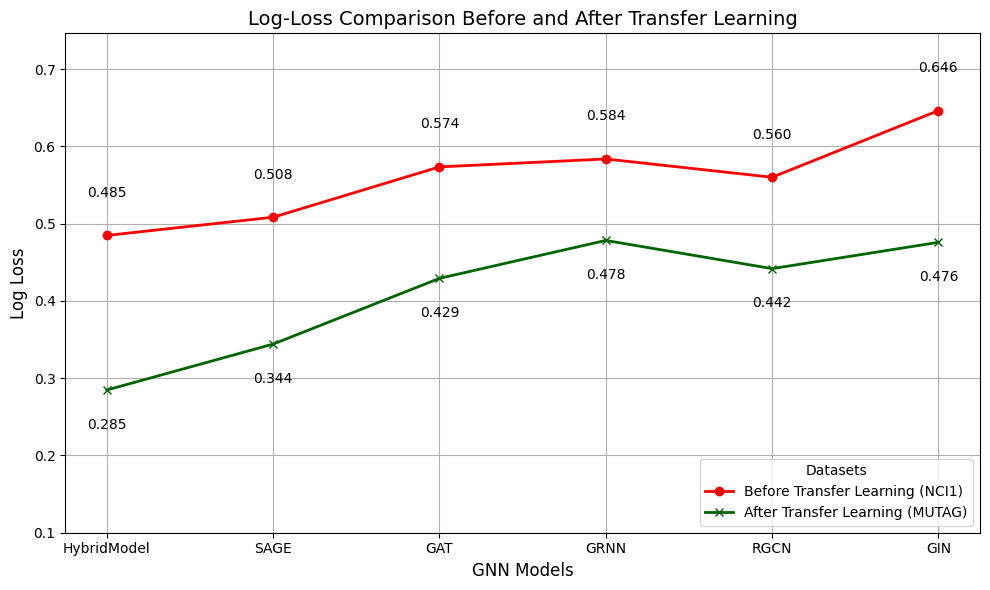

In [1]:
import matplotlib.pyplot as plt

# Data
models = ['HybridModel', 'SAGE', 'GAT', 'GRNN', 'RGCN', 'GIN']
log_loss_before = [0.4847832295636574, 0.50835732, 0.573503517, 0.583753454, 0.560079657, 0.646361608]
log_loss_after = [0.28471271693558353, 0.344181818, 0.42923382, 0.478320334, 0.441808848, 0.475851908]

# Line Plot with enhancements
plt.figure(figsize=(10,6))

# Plot before and after with different markers and line styles (similar to the image example)
plt.plot(models, log_loss_before, marker='o', label='Before Transfer Learning (NCI1)', color='red', linestyle='-', linewidth=2)
plt.plot(models, log_loss_after, marker='x', label='After Transfer Learning (MUTAG)', color='darkgreen', linestyle='-', linewidth=2)

# Add value labels on the lines
for i, v in enumerate(log_loss_before):
    plt.text(i, v + 0.05, f"{v:.3f}", ha='center', color='black')
for i, v in enumerate(log_loss_after):
    plt.text(i, v - 0.05, f"{v:.3f}", ha='center', color='black')

# Highlight the model with the highest and lowest log loss after transfer
max_after = max(log_loss_after)
min_after = min(log_loss_after)
max_index = log_loss_after.index(max_after)
min_index = log_loss_after.index(min_after)

# Set y-axis limits to start at 0.0 and leave enough space for labels
plt.ylim(0.1, max(max(log_loss_before), max(log_loss_after)) + 0.1)

# Labels and Titles
plt.xlabel('GNN Models', fontsize=12)
plt.ylabel('Log Loss', fontsize=12)
plt.title('Log-Loss Comparison Before and After Transfer Learning', fontsize=14)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

# Add legend to explain different metrics
plt.legend(title="Datasets", fontsize=10, loc='lower right')

# Show grid for better readability
plt.grid(True)

# Display the plot
plt.tight_layout()
plt.show()
